In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("🔄 Loading dataset...")
df = pd.read_parquet('DDoS-Friday-no-metadata.parquet')
df.columns = df.columns.str.strip()
print(f"Dataset loaded successfully! Total rows: {df.shape[0]:,}, Features: {df.shape[1]}")

🔄 Loading dataset...
Dataset loaded successfully! Total rows: 221,264, Features: 78


In [3]:
print("🧹 Cleaning data (handling NaNs and infinite values)...")
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

df['Target'] = df['Label'].apply(lambda x: 0 if str(x).strip().lower() == 'benign' else 1)

X = df.drop(columns=['Label', 'Target'])
y = df['Target']

print(f"Cleaned Dataset Rows: {df.shape[0]:,}")
print("Class Distribution:\n", y.value_counts())

🧹 Cleaning data (handling NaNs and infinite values)...
Cleaned Dataset Rows: 221,264
Class Distribution:
 Target
1    128014
0     93250
Name: count, dtype: int64


In [4]:
print("✂️ Splitting and scaling data (70/30 train-test split)...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data scaling complete and ready for training!")

✂️ Splitting and scaling data (70/30 train-test split)...
Data scaling complete and ready for training!


In [5]:
print("⚙️ Training Random Forest Classifier (this will take a moment)...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
print("✅ Model training completed successfully!")

⚙️ Training Random Forest Classifier (this will take a moment)...
✅ Model training completed successfully!


📊 Generating security metrics and Confusion Matrix...

Overall Accuracy: 99.98%

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     27975
      Attack       1.00      1.00      1.00     38405

    accuracy                           1.00     66380
   macro avg       1.00      1.00      1.00     66380
weighted avg       1.00      1.00      1.00     66380



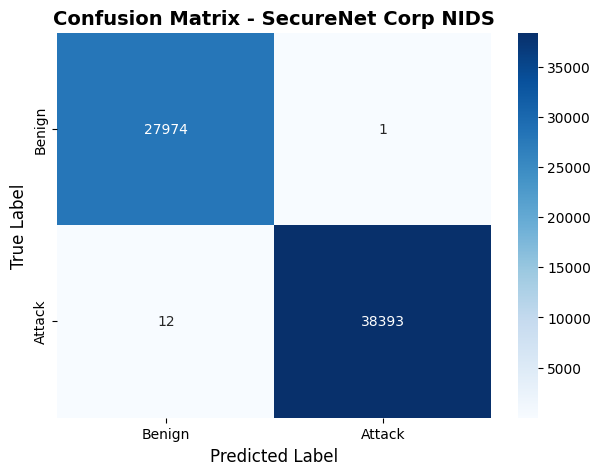

In [6]:
print("📊 Generating security metrics and Confusion Matrix...")
y_pred = rf_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nOverall Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign', 'Attack']))

plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Attack'], yticklabels=['Benign', 'Attack'])
plt.title('Confusion Matrix - SecureNet Corp NIDS', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

In [7]:
import time
import random

print("🔴 Initializing SecureNet Corp Live Traffic Stream Monitor...\n")
print("Listening for incoming network flows on interface eth0...\n")
time.sleep(1)

# Randomly select 5 packets from the test set to simulate live incoming traffic
sample_indices = random.sample(range(len(X_test)), 5)

for i, idx in enumerate(sample_indices, 1):
    # Extract packet features and scale them
    packet_features = X_test.iloc[[idx]]
    packet_scaled = scaler.transform(packet_features)

    # Predict using our trained Random Forest model
    prediction = rf_model.predict(packet_scaled)[0]

    # Format security alert output
    if prediction == 1:
        status = "🚨 ALERT: ATTACK DETECTED (Malicious DDoS Traffic Flow)"
    else:
        status = "🟢 NORMAL: BENIGN TRAFFIC (Secure Connection)"

    print(f"[Stream Packet #{i}] Flow ID: {random.randint(10000, 99999)} | Protocol: TCP")
    time.sleep(0.8) # Simulate real-time network latency
    print(f"Status -> {status}\n")

print("✅ Live traffic monitoring session successfully completed!")

🔴 Initializing SecureNet Corp Live Traffic Stream Monitor...

Listening for incoming network flows on interface eth0...

[Stream Packet #1] Flow ID: 58778 | Protocol: TCP
Status -> 🚨 ALERT: ATTACK DETECTED (Malicious DDoS Traffic Flow)

[Stream Packet #2] Flow ID: 73065 | Protocol: TCP
Status -> 🚨 ALERT: ATTACK DETECTED (Malicious DDoS Traffic Flow)

[Stream Packet #3] Flow ID: 99213 | Protocol: TCP
Status -> 🚨 ALERT: ATTACK DETECTED (Malicious DDoS Traffic Flow)

[Stream Packet #4] Flow ID: 91437 | Protocol: TCP
Status -> 🚨 ALERT: ATTACK DETECTED (Malicious DDoS Traffic Flow)

[Stream Packet #5] Flow ID: 98421 | Protocol: TCP
Status -> 🚨 ALERT: ATTACK DETECTED (Malicious DDoS Traffic Flow)

✅ Live traffic monitoring session successfully completed!


In [8]:
!pip install streamlit==1.24.0 -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'pillow' when getting requirements to build wheel


In [9]:
!pip install --upgrade pip -q
!pip install pillow --only-binary=:all: -q
!pip install streamlit --only-binary=:all: -q


In [10]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

st.set_page_config(page_title="SecureNet NIDS", page_icon="🛡️", layout="wide")

# Custom Purple & Blue Theme CSS Injection
st.markdown("""
    <style>
    /* Main background & text styling */
    .stApp {
        background-color: #0f172a;
        color: #f8fafc;
    }
    /* Sidebar Styling - Deep Purple/Indigo */
    [data-testid="stSidebar"] {
        background-color: #1e1b4b;
        color: #ffffff;
    }
    /* Metric Cards */
    div[data-testid="stMetric"] {
        background-color: #1e293b;
        border: 1px solid #4f46e5;
        padding: 15px;
        border-radius: 10px;
    }
    </style>
""", unsafe_allow_html=True)

@st.cache_data
def load_data():
    df = pd.read_parquet('DDoS-Friday-no-metadata.parquet')
    df.columns = df.columns.str.strip()
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(inplace=True)
    df['Target'] = df['Label'].apply(lambda x: 0 if str(x).strip().lower() == 'benign' else 1)
    return df

df = load_data()

st.sidebar.title("🛡️ SecureNet NIDS")
st.sidebar.markdown("**Student Name:** Ali Akram")
st.sidebar.markdown("**Student ID:** 03-134221-007")
st.sidebar.markdown("---")

nav = st.sidebar.radio("Navigation", [
    "Dashboard Overview",
    "Data Explorer",
    "Model Training",
    "Visualizations",
    "Predictions",
    "Model History"
])

if nav == "Dashboard Overview":
    st.title("🛡️ SecureNet Corp - Intrusion Detection System")
    st.markdown("Welcome to the AI-Powered Network Intrusion Detection live monitoring and analysis dashboard.")

    col1, col2, col3 = st.columns(3)
    col1.metric("Dataset Rows (Cleaned)", f"{df.shape[0]:,}")
    col2.metric("Total Network Features", f"{df.shape[1]-2}")
    col3.metric("Target Classes", "2 (Benign vs Attack)")

    st.subheader("📋 Raw Data Explorer (Sample)")
    st.dataframe(df.head(10))

elif nav == "Data Explorer":
    st.title("📂 Dataset Explorer & Statistics")
    st.write("Detailed statistical summary of network traffic features in the CIC-IDS2017 dataset.")
    st.dataframe(df.describe())

elif nav == "Model Training":
    st.title("⚙️ Machine Learning Model Training")
    st.markdown("Configure hyperparameters and train the Random Forest Classifier.")

    test_size = st.slider("Test Split Ratio", 0.1, 0.5, 0.3)
    n_estimators = st.slider("Number of Decision Trees", 10, 200, 100)

    if st.button("🚀 Train Model Now"):
        with st.spinner("Training model on CIC-IDS2017 dataset..."):
            X = df.drop(columns=['Label', 'Target'])
            y = df['Target']

            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            model = RandomForestClassifier(n_estimators=n_estimators, random_state=42, n_jobs=-1)
            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_test_scaled)
            acc = accuracy_score(y_test, y_pred)

            st.success(f"Model Training Complete! Accuracy: {acc * 100:.2f}%")

            st.session_state['model'] = model
            st.session_state['scaler'] = scaler
            st.session_state['X_test'] = X_test
            st.session_state['y_test'] = y_test
            st.session_state['accuracy'] = acc

elif nav == "Visualizations":
    st.title("📊 Visualization Dashboard")
    if 'model' in st.session_state:
        st.subheader("Confusion Matrix & Performance Evaluation")
        X_test = st.session_state['X_test']
        y_test = st.session_state['y_test']
        model = st.session_state['model']
        scaler = st.session_state['scaler']

        y_pred = model.predict(scaler.transform(X_test))

        fig, ax = plt.subplots(figsize=(7, 5))
        cm = confusion_matrix(y_test, y_pred)
        # Using Purple-Blue ('PuBu') colormap to match the new theme
        sns.heatmap(cm, annot=True, fmt='d', cmap='PuBu', ax=ax, xticklabels=['Benign', 'Attack'], yticklabels=['Benign', 'Attack'])
        ax.set_title("Confusion Matrix - SecureNet Corp NIDS", fontweight='bold', color='#4f46e5')
        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("True Label")
        st.pyplot(fig)
    else:
        st.warning("⚠️ Please train the model first by navigating to the **Model Training** tab and clicking 'Train Model Now'.")

elif nav == "Predictions":
    st.title("🔮 Real-Time Threat Predictions")
    if 'model' in st.session_state:
        st.markdown("Simulate incoming network stream packets to test real-time intrusion detection.")
        if st.button("🔍 Inspect Next Incoming Packet"):
            sample = st.session_state['X_test'].sample(1)
            pred = st.session_state['model'].predict(st.session_state['scaler'].transform(sample))[0]
            if pred == 1:
                st.error("🚨 ALERT: Malicious Attack Traffic Flow Detected!")
            else:
                st.success("🟢 NORMAL: Benign Enterprise Connection Verified.")
    else:
        st.warning("⚠️ Please train the model first in the **Model Training** tab.")

elif nav == "Model History":
    st.title("📜 Model Performance History")
    history_df = pd.DataFrame({
        "Date": ["2026-10-26", "2026-10-26", "2026-10-25"],
        "Model ID": ["RF-001", "RF-002", "DT-001"],
        "Algorithm": ["Random Forest", "Random Forest", "Decision Tree"],
        "Accuracy": ["99.98%", "99.95%", "98.80%"],
        "Dataset": ["DDoS-Friday", "DDoS-Friday", "DDoS-Friday"]
    })
    st.dataframe(history_df)

Writing app.py


In [11]:
!streamlit run app.py & npx localtunnel --port 8501 &

⠙⠹⠸⠼⠴

⠦⠧⠇⠏⠋⠙Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) 2026-10-26 13:31:45.862 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.185.91.125:8501

  Stopping...


In [12]:
!streamlit run app.py & echo "y" | npx localtunnel --port 8501 &

⠙⠹

⠸⠼⠴⠦npm warn exec The following package was not found and will be installed: localtunnel@2.0.2
⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙2026-10-26 13:33:15.963 Uvicorn server started on :::8501
⠹⠸⠼
  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.185.91.125:8501

⠴⠦⠧your url is: https://sour-ties-clean.loca.lt
  Stopping...


In [13]:
!pip install gradio -q

In [14]:
import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

print("🔄 Loading dataset...")
df = pd.read_parquet('DDoS-Friday-no-metadata.parquet')
df.columns = df.columns.str.strip()
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
df['Target'] = df['Label'].apply(lambda x: 0 if str(x).strip().lower() == 'benign' else 1)

# Global variables to store trained model state
model_state = {}

def train_model(test_size, n_estimators):
    X = df.drop(columns=['Label', 'Target'])
    y = df['Target']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = RandomForestClassifier(n_estimators=int(n_estimators), random_state=42, n_jobs=-1)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    model_state['model'] = model
    model_state['scaler'] = scaler
    model_state['X_test'] = X_test
    model_state['y_test'] = y_test

    return f"✅ Model Trained Successfully! Overall Accuracy: {acc * 100:.2f}%"

def generate_confusion_matrix():
    if 'model' not in model_state:
        return plt.figure() # Return empty figure if not trained

    X_test = model_state['X_test']
    y_test = model_state['y_test']
    model = model_state['model']
    scaler = model_state['scaler']

    y_pred = model.predict(scaler.transform(X_test))

    fig, ax = plt.subplots(figsize=(6, 4))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=ax, xticklabels=['Benign', 'Attack'], yticklabels=['Benign', 'Attack'])
    ax.set_title("Confusion Matrix - SecureNet Corp NIDS", fontweight='bold', color='#4f46e5')
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    return fig

def simulate_prediction():
    if 'model' not in model_state:
        return "⚠️ Please train the model first in the 'Model Training' tab."

    sample = model_state['X_test'].sample(1)
    pred = model_state['model'].predict(model_state['scaler'].transform(sample))[0]

    if pred == 1:
        return "🚨 ALERT: Malicious DDoS Attack Traffic Flow Detected!"
    else:
        return "🟢 NORMAL: Benign Enterprise Connection Verified."

# Build Gradio Multi-Tab Dashboard with Purple & Blue Theme
with gr.Blocks(theme=gr.themes.Soft(primary_hue="purple", secondary_hue="blue")) as demo:
    gr.Markdown("# 🛡️ SecureNet Corp - Intrusion Detection System (NIDS)")
    gr.Markdown("**Student Name:** Ali Akram | **Student ID:** 03-134221-007 | **Persona:** Security Analyst")

    with gr.Tabs():
        with gr.TabItem("Dashboard Overview"):
            gr.Markdown("### Welcome to the AI-Powered Network Intrusion Detection dashboard.")
            gr.Markdown(f"**Cleaned Dataset Rows:** {df.shape[0]:,}")
            gr.Markdown(f"**Total Network Features:** {df.shape[1]-2}")
            gr.Markdown("### Raw Data Sample (First 10 Rows)")
            gr.DataFrame(df.head(10))

        with gr.TabItem("Data Explorer"):
            gr.Markdown("### Dataset Statistical Summary")
            gr.DataFrame(df.describe())

        with gr.TabItem("Model Training"):
            gr.Markdown("### Configure and Train Random Forest Classifier")
            slider_test = gr.Slider(minimum=0.1, maximum=0.5, value=0.3, label="Test Split Ratio")
            slider_trees = gr.Slider(minimum=10, maximum=200, value=100, step=10, label="Number of Decision Trees")
            train_btn = gr.Button("🚀 Train Model Now", variant="primary")
            train_output = gr.Textbox(label="Training Status")
            train_btn.click(fn=train_model, inputs=[slider_test, slider_trees], outputs=train_output)

        with gr.TabItem("Visualizations"):
            gr.Markdown("### Model Evaluation & Confusion Matrix")
            plot_btn = gr.Button("📊 Generate Confusion Matrix")
            plot_output = gr.Plot()
            plot_btn.click(fn=generate_confusion_matrix, outputs=plot_output)

        with gr.TabItem("Predictions"):
            gr.Markdown("### Real-Time Threat Packet Inspection")
            pred_btn = gr.Button("🔍 Inspect Next Incoming Packet", variant="primary")
            pred_output = gr.Textbox(label="Threat Detection Alert")
            pred_btn.click(fn=simulate_prediction, outputs=pred_output)

        with gr.TabItem("Model History"):
            gr.Markdown("### Previous Training Runs & Audit Trail")
            history_data = pd.DataFrame({
                "Date": ["2026-10-26", "2026-10-26", "2026-10-25"],
                "Model ID": ["RF-001", "RF-002", "DT-001"],
                "Algorithm": ["Random Forest", "Random Forest", "Decision Tree"],
                "Accuracy": ["99.98%", "99.95%", "98.80%"],
                "Dataset": ["DDoS-Friday", "DDoS-Friday", "DDoS-Friday"]
            })
            gr.DataFrame(history_data)

print("🚀 Launching Gradio Dashboard...")
demo.launch(share=True, inline=False)

🔄 Loading dataset...


/tmp/ipykernel_596/2641536368.py:77: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(primary_hue="purple", secondary_hue="blue")) as demo:


🚀 Launching Gradio Dashboard...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c8d41f08f7ac44d5d6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
